In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import glob
import os
from statsmodels.stats.multitest import fdrcorrection as fdr
from scipy import stats
import statsmodels.stats.multitest as sm 
df_PD = pd.read_csv('/home/MRMelissaGrantPeters/MinaRyten/Melissa/MRIxST/stats/04c-4layers_PDpredictions_withendo_with_PrD/Projected_PD_pathway_scores_no_SWM.csv')
df_PD['SpDregion'] = df_PD['SpD']+df_PD['region']
df_PD = df_PD.set_index('SpDregion')

In [2]:
df_PD

,SpD,region,Inhib_PD_predicted,inflammation_GO0001660_PD_predicted,inflammation_GO0001774_PD_predicted,inflammation_GO0001788_PD_predicted,inflammation_GO0002232_PD_predicted,inflammation_GO0002248_PD_predicted,inflammation_GO0002265_PD_predicted,inflammation_GO0002269_PD_predicted,...,myelin_GO0043615_PD_predicted,myelin_GO0045163_PD_predicted,myelin_GO0048709_PD_predicted,myelin_GO0048713_PD_predicted,myelin_GO0048714_PD_predicted,myelin_GO0048715_PD_predicted,myelin_GO0070445_PD_predicted,myelin_GO0070447_PD_predicted,myelin_GO0097252_PD_predicted,myelin_GO1904141_PD_predicted
SpDregion,,,,,,,,,,,,,,,,,,,,,
SpD4anterior,SpD4,anterior,88.161711,-0.009275,2.669591,-0.031005,-0.029643,-0.031901,0.876695,-0.031083,...,-0.064034,0.160095,0.517350,-0.006837,-0.060682,-0.045018,0.035688,-0.038929,0.006314,-0.019965
SpD3anterior,SpD3,anterior,134.252165,-0.010777,2.770106,-0.035289,-0.009598,-0.040993,0.945578,-0.035975,...,-0.070670,0.197674,0.474513,-0.033751,-0.042374,-0.048617,0.042168,-0.047361,0.004078,-0.024495
SpD2anterior,SpD2,anterior,174.359434,-0.012231,3.007690,-0.040038,-0.008415,-0.050690,1.073573,-0.040743,...,-0.084967,0.244193,0.424184,-0.067185,-0.055325,-0.056371,0.042982,-0.059427,0.005251,-0.034670
SpD1anterior,SpD1,anterior,261.252711,-0.014215,3.577158,-0.043449,0.123676,-0.034452,0.935133,-0.043129,...,-0.049643,0.253047,0.397280,-0.087303,0.088507,0.029553,0.086202,-0.072084,-0.008231,-0.014200
SpD4middle,SpD4,middle,60.625916,-0.009496,3.068870,-0.033344,-0.007760,-0.036201,0.992122,-0.032992,...,-0.071636,0.165986,0.536425,-0.003167,-0.041347,-0.017000,0.037237,-0.046517,0.007289,-0.014815
SpD3middle,SpD3,middle,111.771357,-0.010949,3.136490,-0.037539,0.041229,-0.042350,0.992529,-0.037954,...,-0.068983,0.192206,0.503334,-0.021245,0.017096,-0.004033,0.051569,-0.053673,0.000843,-0.010341
SpD2middle,SpD2,middle,161.208534,-0.012381,3.326640,-0.041922,0.031613,-0.050515,1.105556,-0.042200,...,-0.083233,0.241400,0.442287,-0.059495,-0.010962,-0.019704,0.050800,-0.065481,0.002724,-0.023934
SpD1middle,SpD1,middle,234.816878,-0.014489,3.818974,-0.045841,0.149958,-0.042096,1.032814,-0.045817,...,-0.056605,0.256809,0.419544,-0.079753,0.121218,0.051066,0.088402,-0.076788,-0.008937,-0.007126
SpD4posterior,SpD4,posterior,67.650806,-0.009523,2.943617,-0.032193,-0.006715,-0.034236,0.949612,-0.032159,...,-0.065891,0.160557,0.537306,-0.002576,-0.035609,-0.021848,0.039421,-0.042621,0.006387,-0.014951


In [3]:
df_CT = pd.read_csv('/home/MRMelissaGrantPeters/MinaRyten/Melissa/MRIxST/stats/02c-4layers_qMRIvsST_withendo_with_PrD/LOO_predictions_control_qMRI_vs_GO_POI_no_SWM.csv')
df_CT['SpDregion'] = df_CT['SpD']+df_CT['region']
df_CT = df_CT.set_index('SpDregion')

In [5]:
paths = glob.glob('../../processed_data/01b-4layers_withendo/05-pathway_scoring/scores_4*.csv')

interest_paths = ['GO0006954','GO0048713','GO0006631', 'GO0006682', 'GO0014808','GO0030173', 'GO0033280', 'GO0034625','GO0036092', 'GO0042382', 'GO0051861','GO0071007', 'GO0090556', 'GO1990531']

GO0006954


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


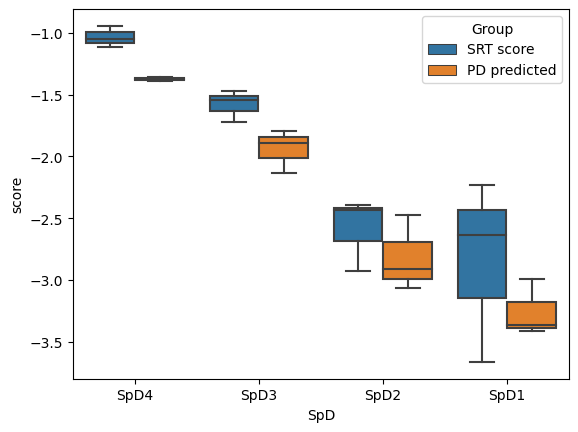

/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


SpD1 Ttest_indResult(statistic=-0.9219470734138675, pvalue=0.40873126143802924)
SpD2 Ttest_indResult(statistic=-0.93016069946263, pvalue=0.4049407527311803)
SpD3 Ttest_indResult(statistic=-2.853721666626874, pvalue=0.04622161387741003)
SpD4 Ttest_indResult(statistic=-6.497152247675083, pvalue=0.0028947100499474555)
          0         1      padj
0 -0.921947  0.408731  0.408731
0 -0.930161  0.404941  0.408731
0 -2.853722  0.046222  0.092443
0 -6.497152  0.002895  0.011579
GO0048713


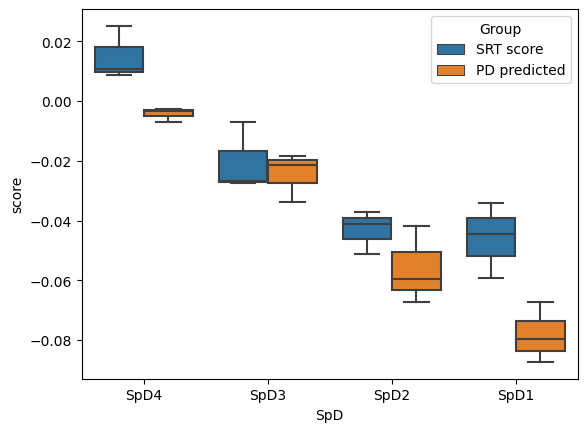

SpD1 Ttest_indResult(statistic=-3.446328692788591, pvalue=0.026142010096731554)
SpD2 Ttest_indResult(statistic=-1.5043105541365696, pvalue=0.20694337408907582)
SpD3 Ttest_indResult(statistic=-0.5013361327822952, pvalue=0.6424691324873557)
SpD4 Ttest_indResult(statistic=-3.5549504354645873, pvalue=0.023693079991705137)
          0         1      padj
0 -3.446329  0.026142  0.052284
0 -1.504311  0.206943  0.275924
0 -0.501336  0.642469  0.642469
0 -3.554950  0.023693  0.052284


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


GO0006631


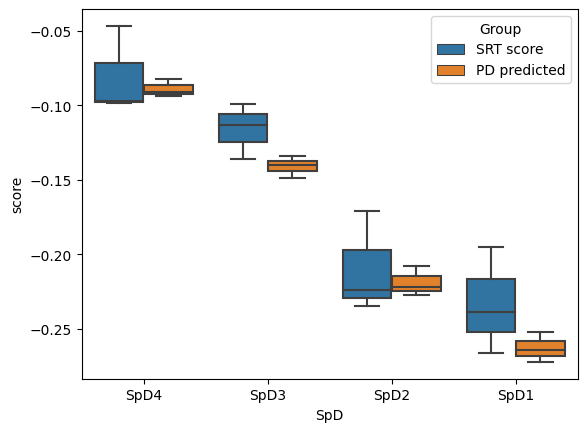

SpD1 Ttest_indResult(statistic=-1.3701009516881346, pvalue=0.2425219753706436)
SpD2 Ttest_indResult(statistic=-0.44657577160363693, pvalue=0.6782923375688166)
SpD3 Ttest_indResult(statistic=-2.1553498088537704, pvalue=0.09739543934164527)
SpD4 Ttest_indResult(statistic=-0.485032625529612, pvalue=0.6530190057908557)
          0         1      padj
0 -1.370101  0.242522  0.485044
0 -0.446576  0.678292  0.678292
0 -2.155350  0.097395  0.389582
0 -0.485033  0.653019  0.678292
GO0006682


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


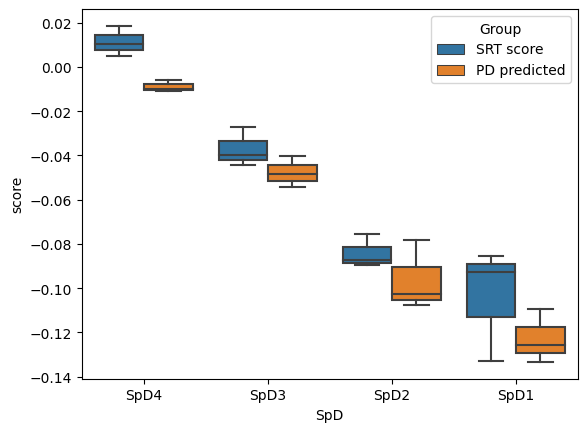

SpD1 Ttest_indResult(statistic=-1.1654384359808967, pvalue=0.30859960942871206)
SpD2 Ttest_indResult(statistic=-1.185171684362692, pvalue=0.30154961847096423)
SpD3 Ttest_indResult(statistic=-1.6137292982364675, pvalue=0.18188453846433003)
SpD4 Ttest_indResult(statistic=-4.753546669710092, pvalue=0.008947531820345257)
          0         1     padj
0 -1.165438  0.308600  0.30860
0 -1.185172  0.301550  0.30860
0 -1.613729  0.181885  0.30860
0 -4.753547  0.008948  0.03579
GO0014808


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


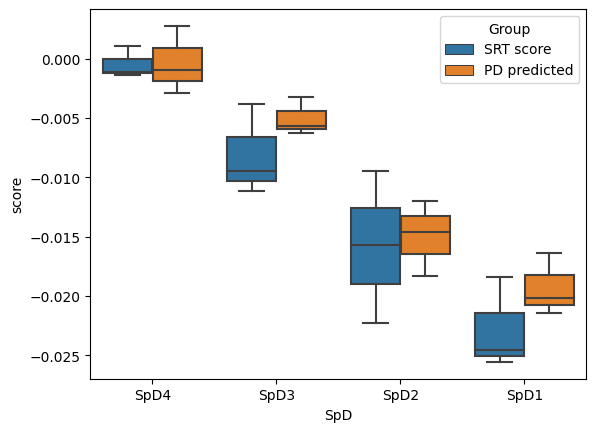

SpD1 Ttest_indResult(statistic=1.3028343713965334, pvalue=0.2625722010034025)
SpD2 Ttest_indResult(statistic=0.2035093994968323, pvalue=0.8486707524314594)
SpD3 Ttest_indResult(statistic=1.2888555502300019, pvalue=0.26693700257835157)
SpD4 Ttest_indResult(statistic=0.06089306945288378, pvalue=0.9543654432030672)
          0         1      padj
0  1.302834  0.262572  0.533874
0  0.203509  0.848671  0.954365
0  1.288856  0.266937  0.533874
0  0.060893  0.954365  0.954365
GO0030173


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


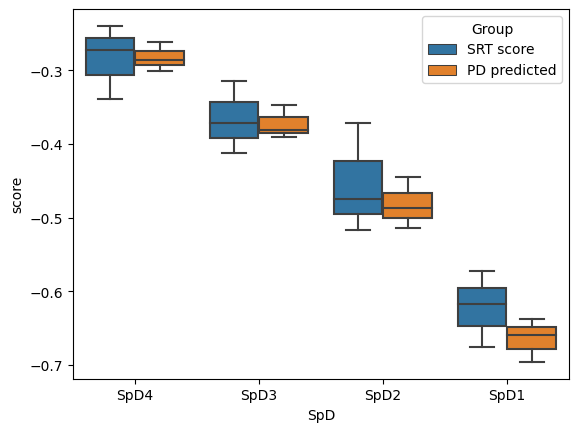

SpD1 Ttest_indResult(statistic=-1.2332379442567638, pvalue=0.2850044678226474)
SpD2 Ttest_indResult(statistic=-0.5931854156293824, pvalue=0.5849711548984269)
SpD3 Ttest_indResult(statistic=-0.21271252143764832, pvalue=0.8419517929969553)
SpD4 Ttest_indResult(statistic=0.04696226399540149, pvalue=0.9647944759406146)
          0         1      padj
0 -1.233238  0.285004  0.964794
0 -0.593185  0.584971  0.964794
0 -0.212713  0.841952  0.964794
0  0.046962  0.964794  0.964794
GO0033280


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


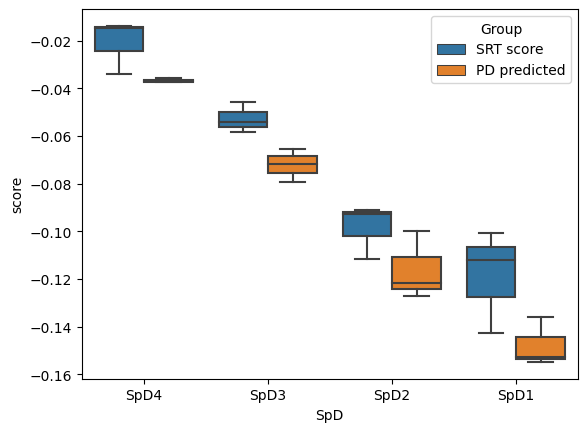

SpD1 Ttest_indResult(statistic=-2.1094746446602555, pvalue=0.10255119336817231)
SpD2 Ttest_indResult(statistic=-1.6817696627097736, pvalue=0.1679059182766645)
SpD3 Ttest_indResult(statistic=-3.551491715266722, pvalue=0.023766734273759426)
SpD4 Ttest_indResult(statistic=-2.4088551615746643, pvalue=0.07364605999191345)
          0         1      padj
0 -2.109475  0.102551  0.136735
0 -1.681770  0.167906  0.167906
0 -3.551492  0.023767  0.095067
0 -2.408855  0.073646  0.136735
GO0034625


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


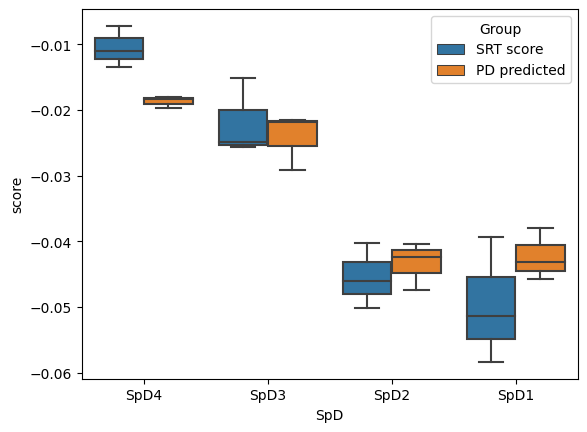

SpD1 Ttest_indResult(statistic=1.234016247183255, pvalue=0.28474376172325444)
SpD2 Ttest_indResult(statistic=0.5982272927307354, pvalue=0.5819136563151067)
SpD3 Ttest_indResult(statistic=-0.5540149301875605, pvalue=0.6090803060410459)
SpD4 Ttest_indResult(statistic=-4.284926236695052, pvalue=0.012797531801430012)
          0         1      padj
0  1.234016  0.284744  0.569488
0  0.598227  0.581914  0.609080
0 -0.554015  0.609080  0.609080
0 -4.284926  0.012798  0.051190
GO0036092


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


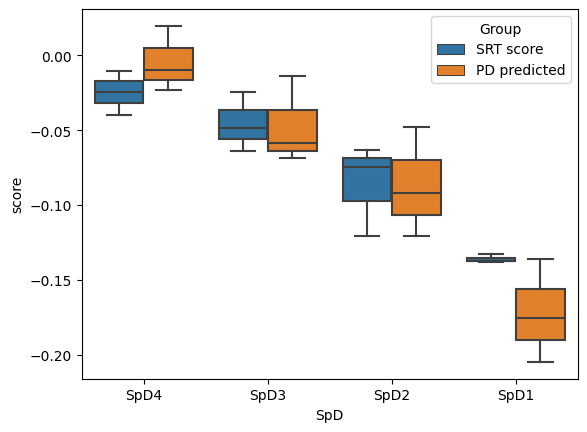

SpD1 Ttest_indResult(statistic=-1.8030369072500974, pvalue=0.14572258658013137)
SpD2 Ttest_indResult(statistic=-0.03067764688178129, pvalue=0.976996274862972)
SpD3 Ttest_indResult(statistic=-0.07387278847965337, pvalue=0.9446583088125846)
SpD4 Ttest_indResult(statistic=1.3535784751339774, pvalue=0.2473032873016072)
          0         1      padj
0 -1.803037  0.145723  0.494607
0 -0.030678  0.976996  0.976996
0 -0.073873  0.944658  0.976996
0  1.353578  0.247303  0.494607
GO0042382


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


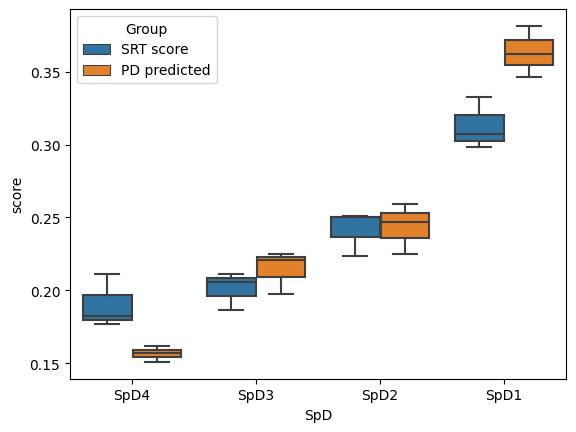

SpD1 Ttest_indResult(statistic=3.492399327349059, pvalue=0.02506823504076897)
SpD2 Ttest_indResult(statistic=0.17250920784013077, pvalue=0.8714140297481787)
SpD3 Ttest_indResult(statistic=1.168408908670904, pvalue=0.3075286366148039)
SpD4 Ttest_indResult(statistic=-3.0530585744314918, pvalue=0.03791469624974761)
          0         1      padj
0  3.492399  0.025068  0.075829
0  0.172509  0.871414  0.871414
0  1.168409  0.307529  0.410038
0 -3.053059  0.037915  0.075829
GO0051861


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


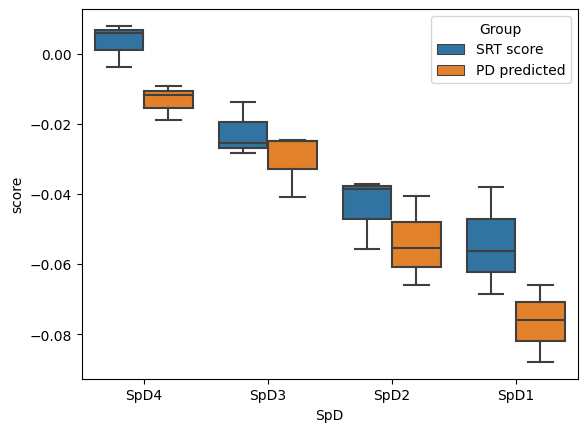

SpD1 Ttest_indResult(statistic=-2.043397105455225, pvalue=0.11051609468900196)
SpD2 Ttest_indResult(statistic=-1.0725338218757856, pvalue=0.34387803644895465)
SpD3 Ttest_indResult(statistic=-1.0977121400341232, pvalue=0.3339709500725218)
SpD4 Ttest_indResult(statistic=-3.6124804084266695, pvalue=0.022506948430713537)
          0         1      padj
0 -2.043397  0.110516  0.221032
0 -1.072534  0.343878  0.343878
0 -1.097712  0.333971  0.343878
0 -3.612480  0.022507  0.090028
GO0071007


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


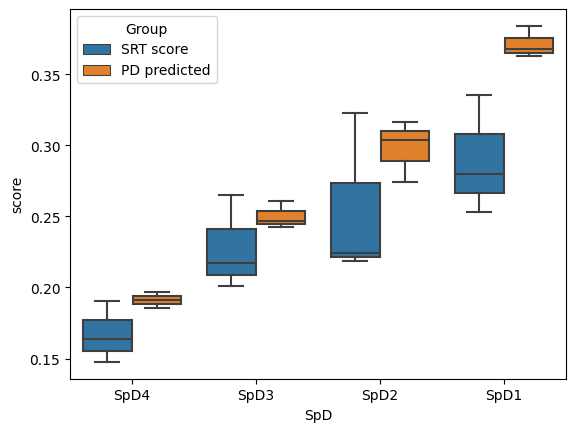

SpD1 Ttest_indResult(statistic=3.2481714138912943, pvalue=0.031430019241123965)
SpD2 Ttest_indResult(statistic=1.1936226685538207, pvalue=0.2985766492698137)
SpD3 Ttest_indResult(statistic=1.0990287281290778, pvalue=0.33346007621019724)
SpD4 Ttest_indResult(statistic=1.8435564139917686, pvalue=0.13902392832331908)
          0         1      padj
0  3.248171  0.031430  0.125720
0  1.193623  0.298577  0.333460
0  1.099029  0.333460  0.333460
0  1.843556  0.139024  0.278048
GO0090556


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


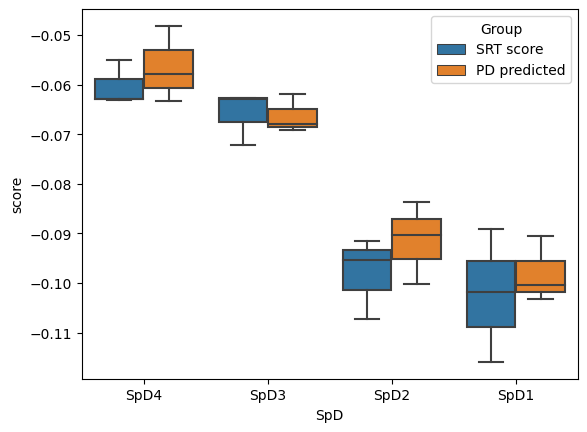

SpD1 Ttest_indResult(statistic=0.48553930269041257, pvalue=0.6526896386884955)
SpD2 Ttest_indResult(statistic=0.9832402670646083, pvalue=0.38115676811868227)
SpD3 Ttest_indResult(statistic=-0.12866110720156548, pvalue=0.9038355134965006)
SpD4 Ttest_indResult(statistic=0.743517093447179, pvalue=0.49846799290281607)
          0         1      padj
0  0.485539  0.652690  0.870253
0  0.983240  0.381157  0.870253
0 -0.128661  0.903836  0.903836
0  0.743517  0.498468  0.870253
GO1990531


/tmp/ipykernel_3693037/954481362.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)


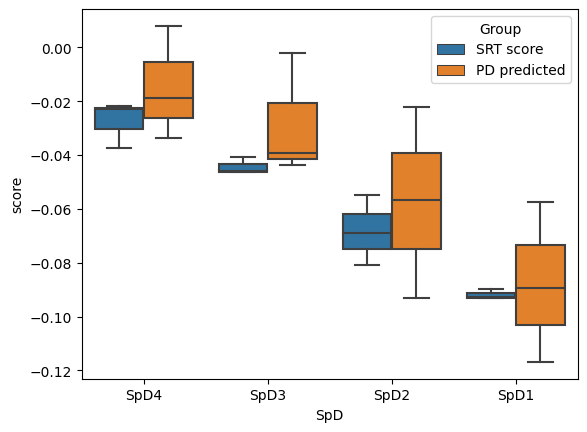

SpD1 Ttest_indResult(statistic=0.23312480938285057, pvalue=0.827108193187635)
SpD2 Ttest_indResult(statistic=0.4931913807288954, pvalue=0.6477270440754754)
SpD3 Ttest_indResult(statistic=1.1923354039827647, pvalue=0.29902771541580997)
SpD4 Ttest_indResult(statistic=0.962357496035098, pvalue=0.39036746888652973)
          0         1      padj
0  0.233125  0.827108  0.827108
0  0.493191  0.647727  0.827108
0  1.192335  0.299028  0.780735
0  0.962357  0.390367  0.780735


In [47]:
for pathway_code in interest_paths:
    
    predicted = df_PD.loc[:, df_PD.columns.str.contains(pathway_code)]
    col_name = str(df_PD.loc[:, df_PD.columns.str.contains(pathway_code)].columns[0])
    predicted.rename(columns = {col_name : 'PD_predicted'}, inplace = True)
    real = pd.read_csv([item for item in paths if pathway_code in item][0], index_col = 0)

    # Create region column
    conditions = [
        real['sample_id'].str.contains('ant'),
        real['sample_id'].str.contains('mid'),
        real['sample_id'].str.contains('post')
    ]
    choices = ['anterior', 'middle', 'posterior']

    real['region'] = np.select(conditions, choices, default='unknown')

    # Rename SpD
    real.rename(columns={'bayesSpace_harmony_7':'SpD'}, inplace = True)

    # Combine SpD and region
    real['SpDregion'] = real['SpD']+real['region']
    med_real = real.groupby('SpDregion').median()
    
    #Join PD predicted and control real
    merged = predicted.merge(med_real, left_index = True, right_index = True, how = 'inner')
    res = []
    
    merged['SpD'] = merged.index.str[:4]
    merged['region'] = merged.index.str[4:]
    
    print(pathway_code)
    
    PD_df = merged[['PD_predicted', 'SpD', 'region']].reset_index()
    PD_df.rename(columns = {'PD_predicted':'score'}, inplace = True)
    PD_df['Group'] = 'PD predicted'
    CT_df = merged[['score', 'SpD', 'region']].reset_index()
    CT_df['Group'] = 'SRT score'
    joint_df = pd.concat([CT_df, PD_df])
    
    sns.boxplot(data = joint_df, x = 'SpD', y = 'score', hue = 'Group')
    plt.show()
    for SpD in ['SpD1','SpD2','SpD3','SpD4']:
        subset = joint_df[joint_df['SpD']==SpD]
        res = stats.ttest_ind(subset[subset['Group']=='PD predicted']['score'], subset[subset['Group']=='SRT score']['score'])
        print(SpD, res)
        if SpD == 'SpD1':
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)
    total_res['padj'] = sm.fdrcorrection(list(total_res[1]), alpha=0.05, method='indep', is_sorted=False)[1]
    print(total_res)
    
    

In [41]:
total_res

,0,1
0,0.233125,0.827108
0,0.493191,0.647727
0,1.192335,0.299028
0,0.962357,0.390367


In [37]:
subset[subset['Group']=='PD predicted']

,SpDregion,score,SpD,region,Group,PD_predicted
0,SpD4anterior,NaN,SpD4,anterior,PD predicted,0.008003
4,SpD4middle,NaN,SpD4,middle,PD predicted,-0.033592
8,SpD4posterior,NaN,SpD4,posterior,PD predicted,-0.018622


In [23]:
joint_df

,SpDregion,score,SpD,region,Group
0,SpD4anterior,0.008003,SpD4,anterior,PD_predicted
1,SpD3anterior,-0.001914,SpD3,anterior,PD_predicted
2,SpD2anterior,-0.022027,SpD2,anterior,PD_predicted
3,SpD1anterior,-0.057444,SpD1,anterior,PD_predicted
4,SpD4middle,-0.033592,SpD4,middle,PD_predicted
5,SpD3middle,-0.043786,SpD3,middle,PD_predicted
6,SpD2middle,-0.056596,SpD2,middle,PD_predicted
7,SpD1middle,-0.089470,SpD1,middle,PD_predicted
8,SpD4posterior,-0.018622,SpD4,posterior,PD_predicted
9,SpD3posterior,-0.039349,SpD3,posterior,PD_predicted
